# Preliminary analysis: post-earnings returns

## 1. Project question
After the first full trading day following a quarterly earnings report, can earnings, price, volume, momentum, and volatility predict the signed stock return over the **next five trading days**? The prediction is made at the close of the reaction day. That day's initial price jump is excluded from the target. The exact release time is unavailable, so this timing is an explicit assumption.

Run `python run_pipeline.py` from the project root before running this notebook. All figures below use real downloaded data.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / 'data' / 'processed' / 'modeling_dataset.csv').exists():
    root = root.parent
data_path = root / 'data' / 'processed' / 'modeling_dataset.csv'
if not data_path.exists():
    raise FileNotFoundError('Run python run_pipeline.py from the project root first.')
df = pd.read_csv(data_path, parse_dates=['reported_date', 'reaction_day', 'prediction_start_date', 'prediction_end_date'])
figures = root / 'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (8, 5), 'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.25})
print(f'Loaded {len(df):,} modeling events.')

Loaded 400 modeling events.


## 2. Dataset overview
Each observation is one ticker's quarterly earnings event. Counts below describe the complete-case modeling dataset, so compare them with the all-events and missingness summaries to see data loss.

In [2]:
overview = pd.DataFrame([{'observations': len(df), 'companies': df['ticker'].nunique(), 'first_report': df['reported_date'].min(), 'last_report': df['reported_date'].max()}])
display(overview)
print('Variables:', ', '.join(df.columns))
display(df.select_dtypes(include='number').describe().T)
direction_counts = pd.Series({'positive': int((df['future_5d_return'] > 0).sum()), 'negative': int((df['future_5d_return'] < 0).sum()), 'zero': int((df['future_5d_return'] == 0).sum())})
display(direction_counts.rename('events').to_frame())

,observations,companies,first_report,last_report
0,400,10,2016-01-14,2025-11-20


Variables: ticker, fiscal_date_ending, reported_date, reaction_day, prediction_start_date, prediction_end_date, earnings_surprise_pct, reported_eps, estimated_eps, earnings_surprise, reaction_day_return, abnormal_volume, return_5d_before, return_20d_before, volatility_20d, spy_return_5d_before, previous_earnings_surprise_pct, future_5d_return, positive_return, positive_return_amount, spy_future_5d_return, market_adjusted_5d_return, required_predictors_missing, valid_target


,count,mean,std,min,25%,50%,75%,max
earnings_surprise_pct,400.0,12.907591,70.159355,-266.666700,1.573250,6.900850,15.582025,960.000000
reported_eps,400.0,1.494095,1.341389,-0.700000,0.475000,1.235000,2.155000,8.020000
estimated_eps,400.0,1.388529,1.194999,-0.600000,0.463250,1.190000,2.040000,6.710000
earnings_surprise,400.0,0.105566,0.287742,-1.540000,0.010000,0.060000,0.190000,1.530000
reaction_day_return,400.0,0.005391,0.057061,-0.263901,-0.019985,0.000035,0.028847,0.298067
abnormal_volume,400.0,2.124396,1.128741,0.674214,1.316472,1.892846,2.581343,9.323869
return_5d_before,400.0,0.008944,0.040344,-0.127083,-0.015377,0.008132,0.032949,0.154907
return_20d_before,400.0,0.030520,0.075822,-0.238885,-0.012619,0.032791,0.068420,0.326169
volatility_20d,400.0,0.016451,0.008707,0.002926,0.010217,0.014349,0.020433,0.059887
spy_return_5d_before,400.0,0.004203,0.021934,-0.085056,-0.006115,0.003904,0.014402,0.082843


,events
positive,223
negative,177
zero,0


## 3. Missing data
Missingness is measured on the less-filtered event file, including unmatched or incomplete events. No financial variable is imputed.

In [3]:
missingness = pd.read_csv(root / 'outputs' / 'missingness_summary.csv')
display(missingness.sort_values('missing_percent', ascending=False).reset_index(drop=True))
display(pd.read_csv(root / 'outputs' / 'data_summary.csv').T.rename(columns={0: 'value'}))

,variable,missing_count,missing_percent
0,reported_date,0,0.0
1,reaction_day,0,0.0
2,spy_future_5d_return,0,0.0
3,positive_return_amount,0,0.0
4,positive_return,0,0.0
5,future_5d_return,0,0.0
6,previous_earnings_surprise_pct,0,0.0
7,spy_return_5d_before,0,0.0
8,volatility_20d,0,0.0
9,return_20d_before,0,0.0


,value
raw_event_count,1105
events_2016_2025,400
events_matched_to_prices,400
events_with_valid_target,400
clean_event_count,400
number_of_tickers,10
start_date,2016-01-14
end_date,2025-11-20
positive_return_count,223
negative_return_count,177


## 4. Preliminary visualizations
These are descriptive plots. A relationship in the scatter plots does not establish a useful out-of-sample forecast.

The earnings-surprise plot shows the central 98% of surprise values so extreme percentages do not obscure the main cluster. The number omitted is printed; all events remain in the dataset and baseline.

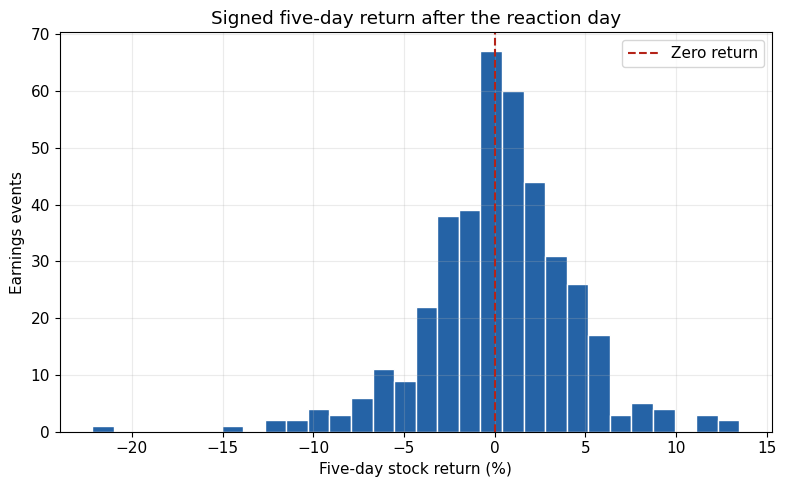

In [4]:
fig, ax = plt.subplots()
ax.hist(df['future_5d_return'].dropna() * 100, bins=30, color='#2563a6', edgecolor='white')
ax.axvline(0, color='#b42318', linestyle='--', linewidth=1.5, label='Zero return')
ax.set(title='Signed five-day return after the reaction day', xlabel='Five-day stock return (%)', ylabel='Earnings events')
ax.legend()
fig.tight_layout()
fig.savefig(figures / 'signed_5d_returns.png', dpi=160)
plt.show()

Earnings surprise vs. following return: 8 extreme events omitted from this plot only.


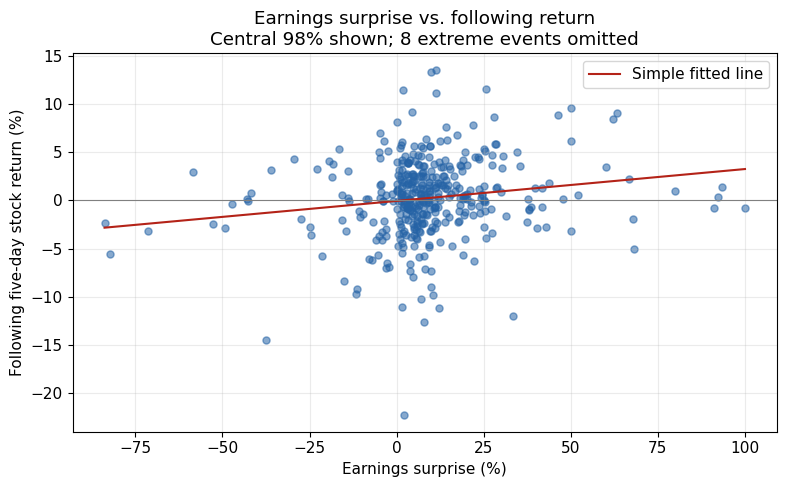

In [5]:
def scatter_with_line(x_col, x_label, title, filename, central_quantiles=None):
    subset = df[[x_col, 'future_5d_return']].dropna()
    omitted = 0
    if central_quantiles is not None:
        lower, upper = subset[x_col].quantile(central_quantiles)
        omitted = int((~subset[x_col].between(lower, upper)).sum())
        subset = subset[subset[x_col].between(lower, upper)]
        print(f'{title}: {omitted} extreme events omitted from this plot only.')
    fig, ax = plt.subplots()
    x = subset[x_col].to_numpy(dtype=float)
    y = subset['future_5d_return'].to_numpy(dtype=float) * 100
    ax.scatter(x, y, alpha=0.55, s=26, color='#2563a6')
    if len(subset) >= 3 and np.unique(x).size >= 2:
        slope, intercept = np.polyfit(x, y, 1)
        line_x = np.linspace(x.min(), x.max(), 100)
        ax.plot(line_x, slope * line_x + intercept, color='#b42318', label='Simple fitted line')
        ax.legend()
    ax.axhline(0, color='gray', linewidth=0.8)
    chart_title = f'{title}\nCentral 98% shown; {omitted} extreme events omitted' if central_quantiles else title
    ax.set(title=chart_title, xlabel=x_label, ylabel='Following five-day stock return (%)')
    fig.tight_layout()
    fig.savefig(figures / filename, dpi=160)
    plt.show()

scatter_with_line('earnings_surprise_pct', 'Earnings surprise (%)', 'Earnings surprise vs. following return', 'surprise_vs_future_return.png', central_quantiles=(0.01, 0.99))

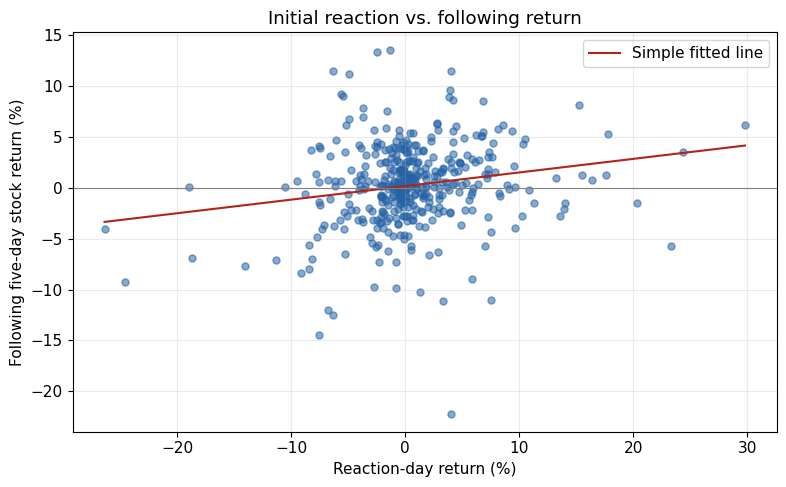

In [6]:
df['reaction_day_return_pct'] = df['reaction_day_return'] * 100
scatter_with_line('reaction_day_return_pct', 'Reaction-day return (%)', 'Initial reaction vs. following return', 'reaction_vs_future_return.png')
# A positive slope may suggest continuation; a negative slope may suggest reversal.

## 5. Optional chronological linear regression baseline
The target here is the signed market-adjusted five-day return. Training uses 2016-2022, validation 2023-2024, and testing 2025. This simple comparison is for TA discussion only. The split is chronological and never shuffled.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

predictors = ['earnings_surprise_pct', 'reported_eps', 'estimated_eps', 'earnings_surprise', 'reaction_day_return', 'abnormal_volume', 'return_5d_before', 'return_20d_before', 'volatility_20d', 'spy_return_5d_before', 'previous_earnings_surprise_pct']
target = 'market_adjusted_5d_return'
train = df[df['reported_date'].dt.year.between(2016, 2022) & df['prediction_end_date'].lt('2023-01-01')]
validation = df[df['reported_date'].dt.year.between(2023, 2024) & df['prediction_end_date'].lt('2025-01-01')]
test = df[df['reported_date'].dt.year.eq(2025)]
if min(len(train), len(validation), len(test)) == 0:
    print('Baseline skipped: at least one chronological period has no complete observations.')
else:
    model = LinearRegression().fit(train[predictors], train[target])
    rows = []
    for label, period in [('validation', validation), ('test', test)]:
        predictions = model.predict(period[predictors])
        rows.append({'period': label, 'observations': len(period), 'MAE': mean_absolute_error(period[target], predictions), 'RMSE': np.sqrt(mean_squared_error(period[target], predictions))})
    display(pd.DataFrame(rows))

,period,observations,MAE,RMSE
0,validation,80,0.023810,0.030848
1,test,40,0.028762,0.036055


## Questions for MTA

1. Is using the first trading day after `reportedDate` as the initial reaction day reasonable when exact before-market/after-market release times are unavailable?
2. Should the final regression target be raw signed five-day return or market-adjusted five-day return relative to SPY?
3. Since the application focuses on positive returns, should we model signed returns and use positive predictions for the application, or restrict the response variable to positive returns?
4. Is approximately 100 large-cap stocks from 2016-2025 a sufficient scope?